In [162]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md


# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [163]:
TRAIN_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/train.csv'
TEST_PATH  = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/test.csv'
SAMPLE_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/sample_submission.csv'
VALID_PATH = 'D:/Code/Omahti-oprec/bike-rush-omahti/data/valid.csv'

_tr = pd.read_csv(TRAIN_PATH)
_te = pd.read_csv(TEST_PATH)

sample = pd.read_csv(SAMPLE_PATH)

N_TRAIN = len(_tr)

# gabungkan train + test agar cleaning identik; baris test punya target NaN
df_train = pd.concat([_tr, _te], ignore_index=True)
print(df_train.shape, N_TRAIN)

(6665, 15) 4728


In [164]:
pd.set_option('display.max_rows', 100)

In [199]:
df_train.head(20)

,Id,day_of_week,temperature_c,humidity_pct,wind_speed_ms,visibility_10m,dew_point_c,solar_radiation_mjm2,rainfall_mm,snowfall_cm,season,holiday,rented_bike_count,temp_zscore_month,month_sin,month_cos,hour_sin,hour_cos,is_weekend
0,bk_754f4e10a46336bbbcb9,3,4.89,49.60,4.11,1174.74,-4.86,1.08,0.00,0.0,3,0,331.0,1.233044,8.660254e-01,5.000000e-01,-5.000000e-01,-0.866025,0
1,bk_b173e94a44f9021b66a8,6,-2.40,29.84,2.69,0.00,-17.57,1.38,0.00,0.0,3,0,181.0,-0.144662,8.660254e-01,5.000000e-01,-7.071068e-01,-0.707107,1
2,bk_c2929a145ff14a2b66eb,4,29.60,62.87,2.77,1923.20,21.52,1.77,0.00,0.0,2,0,999.0,0.563858,-5.000000e-01,-8.660254e-01,-5.000000e-01,-0.866025,0
3,bk_bfb1af02d9c8a82b7051,2,4.33,32.29,1.20,1760.17,-11.32,0.00,0.00,0.0,4,0,846.0,-0.061214,-5.000000e-01,8.660254e-01,-7.071068e-01,0.707107,0
4,bk_4111f3bffd8d14296138,0,22.99,56.29,1.91,562.78,13.70,0.32,0.00,0.0,1,0,2236.0,0.959451,5.000000e-01,-8.660254e-01,-9.659258e-01,0.258819,0
5,bk_d39fb4499a3a94d60c8c,1,-1.95,69.08,3.43,1976.90,-7.12,0.00,0.00,0.0,3,0,85.0,-0.032036,-2.449294e-16,1.000000e+00,5.000000e-01,0.866025,0
6,bk_a1dd5f0b6d564a169af9,6,-2.67,0.00,0.96,1060.21,-11.75,0.00,0.00,0.0,3,0,32.0,0.204005,5.000000e-01,8.660254e-01,9.659258e-01,0.258819,1
7,bk_f8b57b7efee8aa892bf7,4,27.93,57.82,2.39,775.74,18.51,2.66,0.00,0.0,2,0,1175.0,1.054081,1.224647e-16,-1.000000e+00,-5.000000e-01,-0.866025,0
8,bk_6727dc6ad5e07cc6bed1,6,18.88,31.48,2.34,1937.88,1.29,2.38,0.00,0.0,4,0,1767.0,1.309985,-8.660254e-01,5.000000e-01,-5.000000e-01,-0.866025,1
9,bk_85618834e6bc184299ef,2,-5.46,53.99,1.43,1949.48,-13.58,0.00,0.00,0.0,3,0,291.0,-0.249775,5.000000e-01,8.660254e-01,-5.000000e-01,0.866025,0


# EDA

Cek cell yang kosong

In [166]:
df_train.isna().sum()

Id                         0
month                      0
day_of_week                0
hour                       0
temperature_c            167
humidity_pct             140
wind_speed_ms            161
visibility_10m           171
dew_point_c              180
solar_radiation_mjm2     165
rainfall_mm              155
snowfall_cm              157
season                     0
holiday                    0
rented_bike_count       1937
dtype: int64

Cek apakah ada anomali suhu yang berbeda dari rata rata rata untuk setiap musim

C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1781903856.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1781903856.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x="season", order=seasons, ax=axes[1, 0], palette="Set2")


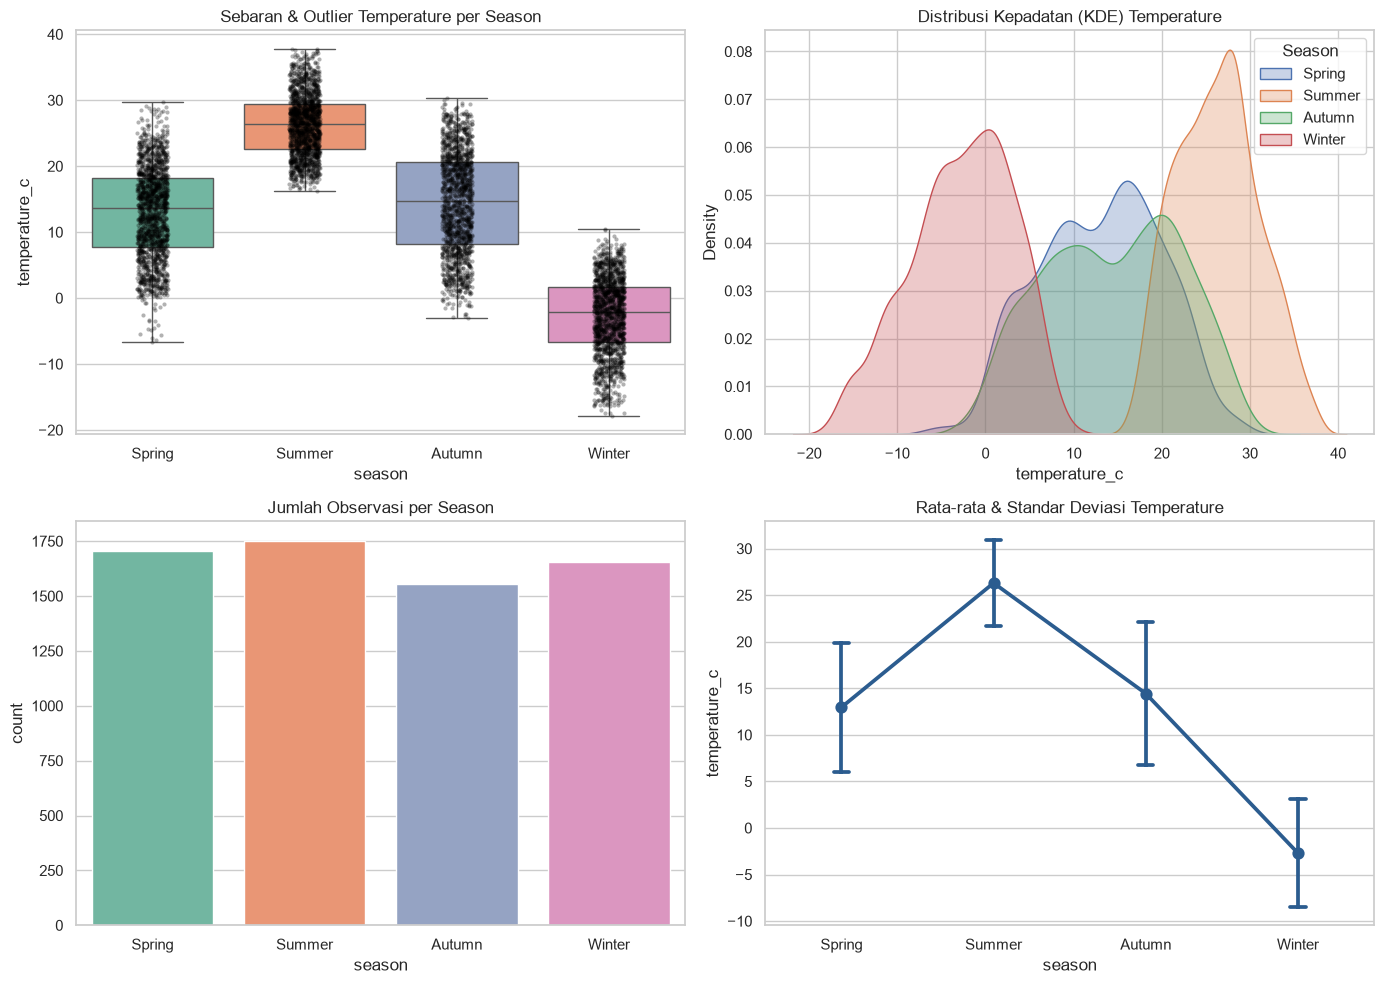

In [167]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# seasons = [1,2,3,4]
seasons = ["Spring","Summer","Autumn","Winter"]


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=df_train, x="season", y="temperature_c", order=seasons, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=df_train, x="season", y="temperature_c", order=seasons, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier Temperature per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in seasons:
    subset = df_train[df_train["season"] == musim]["temperature_c"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) Temperature")
axes[0, 1].legend(title="Season")

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=df_train, x="season", order=seasons, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=df_train, x="season", y="temperature_c", order=seasons,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi Temperature")

plt.tight_layout()
plt.show()

Kita cek ada anomali suhu yang berbeda dari rata rata rata untuk setiap musim

C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1980772207.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\azziy\AppData\Local\Temp\ipykernel_25612\1980772207.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x="month", order=month, ax=axes[1, 0], palette="Set2")


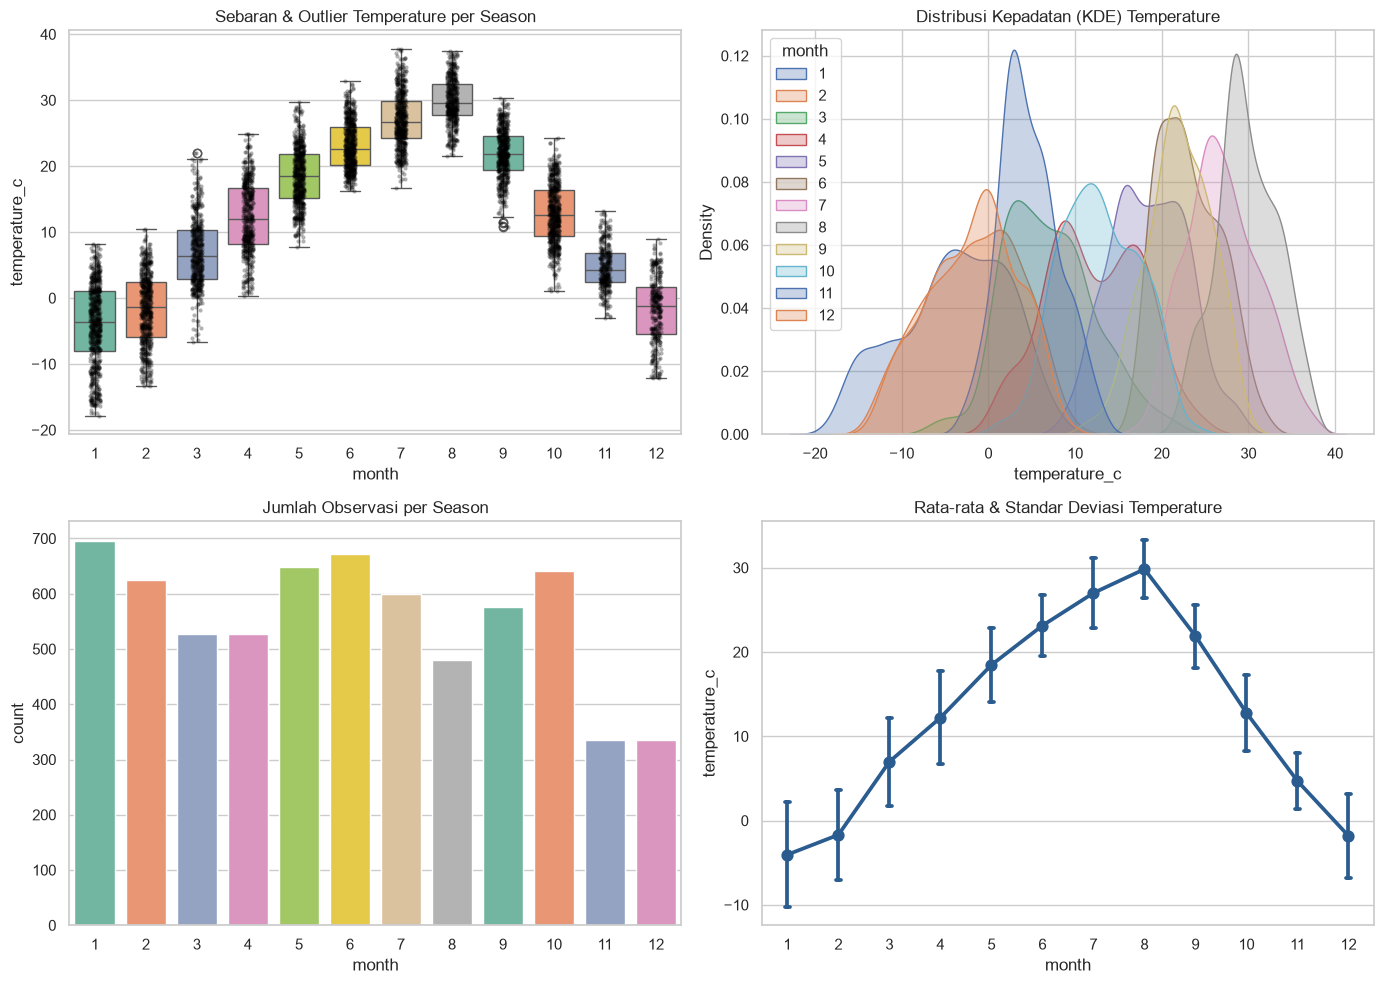

In [168]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

month = [1,2,3,4,5,6,7,8,9,10,11,12]


# 1. Boxplot + Stripplot: Deteksi outlier & sebaran per musim
sns.boxplot(
    data=df_train, x="month", y="temperature_c", order=month, ax=axes[0, 0], palette="Set2"
)
sns.stripplot(
    data=df_train, x="month", y="temperature_c", order=month, ax=axes[0, 0],
    color="black", alpha=0.3, size=3
)
axes[0, 0].set_title("Sebaran & Outlier Temperature per Season")

# 2. KDE Plot: Tumpang tindih distribusi suhu antarmusim
for musim in month:
    subset = df_train[df_train["month"] == musim]["temperature_c"].dropna()
    sns.kdeplot(subset, label=musim, fill=True, alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi Kepadatan (KDE) Temperature")
axes[0, 1].legend(title="month")

# 3. Countplot: Keseimbangan jumlah data per musim
sns.countplot(data=df_train, x="month", order=month, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jumlah Observasi per Season")

# 4. Rata-rata & Standar Deviasi (Pointplot)
sns.pointplot(
    data=df_train, x="month", y="temperature_c", order=month,
    errorbar="sd", capsize=0.1, ax=axes[1, 1], color="#2b5c8f"
)
axes[1, 1].set_title("Rata-rata & Standar Deviasi Temperature")

plt.tight_layout()
plt.show()

In [169]:
df_train.isnull().sum()

Id                         0
month                      0
day_of_week                0
hour                       0
temperature_c            167
humidity_pct             140
wind_speed_ms            161
visibility_10m           171
dew_point_c              180
solar_radiation_mjm2     165
rainfall_mm              155
snowfall_cm              157
season                     0
holiday                    0
rented_bike_count       1937
dtype: int64

# Data Cleaning

### Column Holiday
Replace "holiday" -> 1 and "No holiday" -> 0

In [170]:
df_train['holiday'] = df_train['holiday'].replace('No Holiday','0').replace('Holiday','1').astype(int)
df_train['holiday'].value_counts()

holiday
0    6305
1     360
Name: count, dtype: int64

### Column Seasons

In [171]:
df_train['season'] = df_train['season'].replace('Spring','1').replace('Summer','2').replace('Winter','3').replace('Autumn','4').astype(int)

### Missing Value

In [172]:
df_train = df_train.fillna(0)

# Feature Engineering

Mengisi Misiing valude `temperature_c` dengan rata rata untuk setiap seasons

In [173]:
df_train["temperature_c"] = df_train["temperature_c"].fillna(
    df_train.groupby("season")["temperature_c"].transform("median"))

buat fitur anomali relatif perbulan

In [174]:
month_mean = df_train.groupby("month")["temperature_c"].transform("mean")
month_std = df_train.groupby("month")["temperature_c"].transform("std")

df_train["temp_zscore_month"] = (df_train["temperature_c"] - month_mean) / month_std

Ubah Fitur `month` dan fitur `hour` menjadi fitur sinus supaya model bisa mengenali siklus dari hari dan bulan. lalu drop kolom asli month dan hour

In [175]:
df_train["month_sin"] = np.sin(2 * np.pi * df_train["month"] / 12)
df_train["month_cos"] = np.cos(2 * np.pi * df_train["month"] / 12)

df_train["hour_sin"] = np.sin(2 * np.pi * df_train["hour"] / 24)
df_train["hour_cos"] = np.cos(2 * np.pi * df_train["hour"] / 24)

df_train = df_train.drop(columns=['month','hour'])

Buat fitur baru "is_weekend"

In [193]:
df_train["is_weekend"] = df_train["day_of_week"].isin([5, 6]).astype(int)

# Model Training

karena diawal kita mengabungkan antara train data dan test data maka kita pisahkan kembali keduanya

In [ ]:
train_clean = df_train.iloc[:N_TRAIN].copy()
test_clean = df_train.iloc[N_TRAIN:].drop(columns=['rented_bike_count']).reset_index(drop=True)

Buat variable fitur berisi fitur fitur apa saja yang akan digunakan pada train data

In [178]:
features = train_clean.select_dtypes(include=[np.number]).columns.drop(['id', 'rented_bike_count'], errors='ignore')
features

Index(['day_of_week', 'temperature_c', 'humidity_pct', 'wind_speed_ms',
       'visibility_10m', 'dew_point_c', 'solar_radiation_mjm2', 'rainfall_mm',
       'snowfall_cm', 'season', 'holiday', 'temp_zscore_month', 'month_sin',
       'month_cos', 'hour_sin', 'hour_cos', 'is_weekend'],
      dtype='str')

In [194]:
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import (
    HistGradientBoostingRegressor, 
    RandomForestRegressor
)

x = train_clean[features]
y = train_clean['rented_bike_count']

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=0.1),
    "SVR (RBF Kernel)": SVR(kernel="rbf", C=10.0, epsilon=0.1),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5, weights="distance"),
    "Neural Network (MLP)": MLPRegressor(
        hidden_layer_sizes=(128, 64),
        max_iter=100,
        early_stopping=False,
        validation_fraction=0.1,
        random_state=42,
    ),
    "Random Forest": RandomForestRegressor(),
    "HistGradientBoost" : HistGradientBoostingRegressor()
}


hasil = []
for nama, model in models.items():
    # StandardScaler dipasang di dalam pipeline untuk mencegah data leakage
    pipeline = make_pipeline(StandardScaler(), model)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    hasil.append({
        "Model": nama, 
        "RMSE": round(rmse, 4), 
        "MAE": round(mae, 4), 
        "R2": round(r2, 4)
        })

df_hasil = pd.DataFrame(hasil).sort_values(by="RMSE")
print(df_hasil.to_string(index=False))


d:\Code\Omahti-oprec\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


               Model     RMSE      MAE     R2
   HistGradientBoost 167.7192  99.2159 0.9378
       Random Forest 189.3074 114.6617 0.9208
       KNN Regressor 260.0607 157.9568 0.8504
Neural Network (MLP) 284.1074 190.8828 0.8215
    SVR (RBF Kernel) 434.6146 272.0410 0.5823
          Lasso (L1) 457.8530 344.8939 0.5365
   Linear Regression 457.8813 344.9899 0.5364
          Ridge (L2) 457.8835 344.9666 0.5364


In [195]:
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# 1. Tentukan Fitur (X) dan Target (y)
# Sesuaikan daftar kolom di bawah dengan fitur yang sudah Anda siapkan
x = train_clean[features]
y = train_clean['rented_bike_count']

# 2. Split Data Train (80%) dan Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# 3. Daftar Model yang Sudah Dioptimasi
models = {
    "Neural Network (MLP)": make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64),
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42,
        ),
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1,
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        random_state=42,
    ),
    "SVR (Scaled Target)": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10.0)),
        transformer=StandardScaler(),
    ),
    "KNN Regressor": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=7, weights="distance"),
    ),
    "Ridge (Baseline)": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0),
    ),
}

# 4. Pelatihan & Evaluasi (Membandingkan Performa Train vs Test)
hasil = []
for nama, model in models.items():
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    r2_train = r2_score(y_train, y_train_pred)
    r2_test = r2_score(y_test, y_test_pred)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
    mae_test = mean_absolute_error(y_test, y_test_pred)

    hasil.append({
        "Model": nama,
        "RMSE_Test": round(rmse_test, 4),
        "MAE_Test": round(mae_test, 4),
        "R2_Test": round(r2_test, 4),
        "R2_Train": round(r2_train, 4),
        "Selisih_R2": round(r2_train - r2_test, 4),
    })

df_hasil = pd.DataFrame(hasil).sort_values(by="RMSE_Test")
print(df_hasil.to_string(index=False))

               Model  RMSE_Test  MAE_Test  R2_Test  R2_Train  Selisih_R2
HistGradientBoosting   162.9532   93.4566   0.9413    0.9868      0.0455
       Random Forest   191.0219  115.2379   0.9193    0.9887      0.0693
 SVR (Scaled Target)   208.5301  125.0279   0.9038    0.9393      0.0354
Neural Network (MLP)   242.3960  157.6015   0.8701    0.8780      0.0079
       KNN Regressor   261.0021  159.0031   0.8494    1.0000      0.1506
    Ridge (Baseline)   457.8835  344.9666   0.5364    0.5498      0.0134


In [198]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

x = train_clean[features]
y = train_clean['rented_bike_count']
X_submission = test_clean[features]

final_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    random_state=42,
)

final_model.fit(x, y)

prediksi = final_model.predict(X_submission)
prediksi = np.clip(prediksi, 0, None)

submission = pd.DataFrame({
    'Id': test_clean['Id'],
    'rented_bike_count': np.clip(prediksi, a_min=0, a_max=None)
})

submission.to_csv('D:/Code/Omahti-oprec/bike-rush-omahti/submission.csv', index=False)
print("✅ Selesai! File 'submission.csv' berhasil dibuat.")


✅ Selesai! File 'submission.csv' berhasil dibuat.


### Make submission file

In [181]:
# Submission Predict
final = model.predict(target)
submission = pd.DataFrame({
    'Id': test_clean['Id'],
    'rented_bike_count': np.clip(final, a_min=0, a_max=None)
})

submission.to_csv('D:/Code/Omahti-oprec/bike-rush-omahti/submission.csv', index=False)
print("Score : ",r2)
print("✅ Selesai! File 'submission.csv' berhasil dibuat.")

Score :  0.9283272374446971
✅ Selesai! File 'submission.csv' berhasil dibuat.
